In [138]:
# ==============================================================================
# BLOQUE 1: LIBRERÍAS Y CONFIGURACIÓN DEL ENTORNO
# ==============================================================================
import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Herramientas de Preprocesamiento y Selección de Modelos
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# Modelos No Supervisados (Clustering)
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Modelos Supervisados (Clasificación)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Métricas de Evaluación Supervisada
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, roc_curve
)

# Configuración estética para Matplotlib y Seaborn
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)

# Conectar Google Drive en Colab
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [139]:
# ==============================================================================
# BLOQUE 2: CARGA Y VERIFICACIÓN INICIAL DEL DATASET
# ==============================================================================
path = '/content/drive/MyDrive/Proyecto_IA/data/original/dataset_empleabilidad_estudiantil.csv'

# Cargar dataset
df = pd.read_csv(path)

print("--- INFORMACIÓN INICIAL DEL DATASET ---")
print(f"Dimensiones: {df.shape[0]} filas, {df.shape[1]} columnas\n")

# Preservar una copia limpia original
df_raw = df.copy()

print("--- Primeras 5 filas ---")
display(df.head())

print("\n--- Conteo de Valores Nulos ---")
print(df.isnull().sum())

--- INFORMACIÓN INICIAL DEL DATASET ---
Dimensiones: 45000 filas, 15 columnas

--- Primeras 5 filas ---


,Student_ID,Age,Gender,Degree,Branch,CGPA,Internships,Projects,Coding_Skills,Communication_Skills,Aptitude_Test_Score,Soft_Skills_Rating,Certifications,Backlogs,Placement_Status
0,1048,22,Female,B.Tech,ECE,6.29,0,3,4,6,51,5,1,3,Not Placed
1,37820,20,Female,BCA,ECE,6.05,1,4,6,8,59,8,2,1,Not Placed
2,49668,22,Male,MCA,ME,7.22,1,4,6,6,58,6,2,2,Not Placed
3,19467,22,Male,MCA,ME,7.78,2,4,6,6,90,4,2,0,Placed
4,23094,20,Female,B.Tech,ME,7.63,1,4,6,5,79,6,2,0,Placed



--- Conteo de Valores Nulos ---
Student_ID              0
Age                     0
Gender                  0
Degree                  0
Branch                  0
CGPA                    0
Internships             0
Projects                0
Coding_Skills           0
Communication_Skills    0
Aptitude_Test_Score     0
Soft_Skills_Rating      0
Certifications          0
Backlogs                0
Placement_Status        0
dtype: int64


In [140]:
# ================= ==============================================
# GUARDAR DATASET PROCESADO
# ================================================================
import os

# Crear la carpeta de salida si no existe
os.makedirs('../data/processed', exist_ok=True)

# Guardar el DataFrame limpio
ruta_dataset_procesado = '../data/processed/dataset_empleabilidad_limpio.csv'
df.to_csv(ruta_dataset_procesado, index=False)

print(f"✅ Dataset procesado guardado exitosamente en: {ruta_dataset_procesado}")

✅ Dataset procesado guardado exitosamente en: ../data/processed/dataset_empleabilidad_limpio.csv


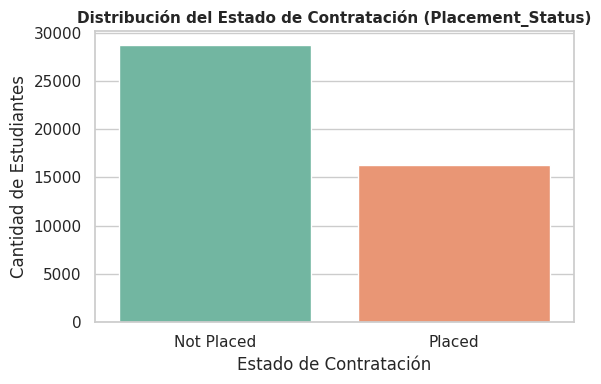

In [141]:
# ==============================================================================
# BLOQUE 3A: GRÁFICO DE BALANCE DE LA VARIABLE OBJETIVO (FIGURA 1)
# ==============================================================================
# Identificar la columna objetivo (Placement Status)
target_col = 'Placement_Status'

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x=target_col, hue=target_col, palette='Set2', legend=False)
plt.title('Distribución del Estado de Contratación (Placement_Status)', fontsize=11, fontweight='bold')
plt.xlabel('Estado de Contratación')
plt.ylabel('Cantidad de Estudiantes')
plt.tight_layout()
plt.show()

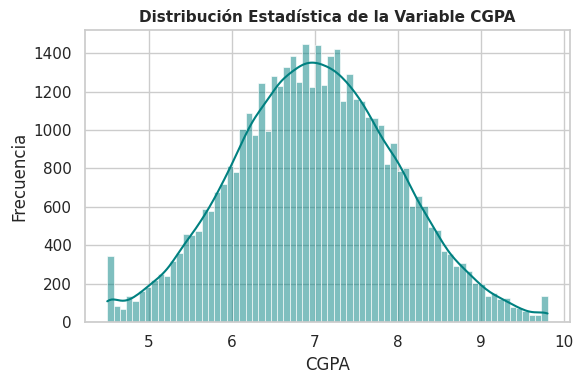

In [142]:
# ==============================================================================
# BLOQUE 3B: HISTOGRAMA DE LA VARIABLE ACADÉMICA CLAVE (FIGURA 2)
# ==============================================================================
# Seleccionar columnas numéricas sin identificadores (IDs)
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
num_cols = [c for c in num_cols if c.lower() not in ['id', 'student_id']]
var_interes = 'CGPA' if 'CGPA' in num_cols else num_cols[0]

plt.figure(figsize=(6, 4))
sns.histplot(df[var_interes], kde=True, color='teal')
plt.title(f'Distribución Estadística de la Variable {var_interes}', fontsize=11, fontweight='bold')
plt.xlabel(var_interes)
plt.ylabel('Frecuencia')
plt.tight_layout()
plt.show()

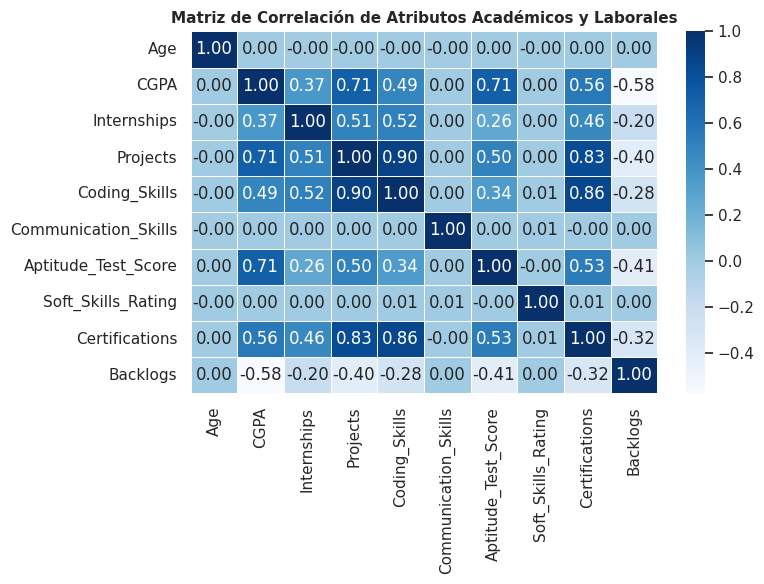

In [143]:
# ==============================================================================
# BLOQUE 3C: MATRIZ DE CORRELACIÓN LIMPIA (FIGURA 4)
# ==============================================================================
# Filtrar solo atributos numéricos académicos/laborales (sin IDs ni clústeres)
plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols].corr(), annot=True, cmap='Blues', fmt='.2f', linewidths=0.5)
plt.title('Matriz de Correlación de Atributos Académicos y Laborales', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

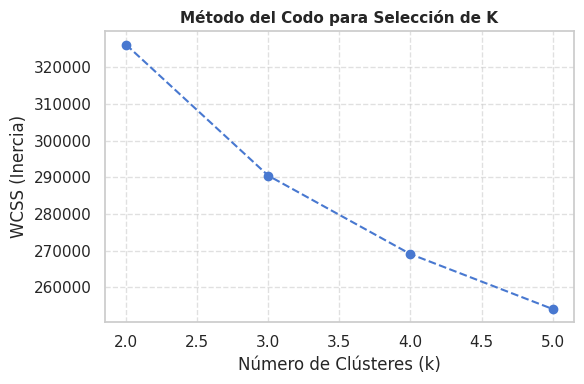

In [144]:
# ==============================================================================
# BLOQUE 4A: MÉTODO DEL CODO PARA SELECCIÓN DE K (FIGURA 3)
# ==============================================================================
# Preparar atributos numéricos escalados solo para clustering
df_features_cluster = df[num_cols].copy()
scaler_cluster = StandardScaler()
df_scaled_cluster = scaler_cluster.fit_transform(df_features_cluster)

# Calcular inercia (WCSS) para el método del codo
wcss = []
k_rango = range(2, 6)

for k in k_rango:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(df_scaled_cluster)
    wcss.append(km.inertia_)

plt.figure(figsize=(6, 4))
plt.plot(k_rango, wcss, marker='o', linestyle='--', color='b')
plt.title('Método del Codo para Selección de K', fontsize=11, fontweight='bold')
plt.xlabel('Número de Clústeres (k)')
plt.ylabel('WCSS (Inercia)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

In [145]:
# ==============================================================================
# BLOQUE 4B: ENTRENAMIENTO DE K-MEANS CON K=3 Y SILHOUETTE SCORE
# ==============================================================================
k_elegido = 3
kmeans_model = KMeans(n_clusters=k_elegido, random_state=42, n_init=10)
cluster_labels = kmeans_model.fit_predict(df_scaled_cluster)

# Guardar la asignación de clústeres en una copia independiente para análisis
df_analisis = df.copy()
df_analisis['Cluster_Perfil'] = cluster_labels

# Cálculo de Silhouette Score sobre muestra de 5,000 registros (evita sobrecarga RAM)
muestra_scaled = df_scaled_cluster[:5000]
muestra_labels = cluster_labels[:5000]
sil_score = silhouette_score(muestra_scaled, muestra_labels)

print(f"--- RESULTADOS K-MEANS (k={k_elegido}) ---")
print(f"Silhouette Score obtenido: {sil_score:.4f}\n")
print("--- Distribución de Estudiantes por Clúster ---")
print(df_analisis['Cluster_Perfil'].value_counts())

--- RESULTADOS K-MEANS (k=3) ---
Silhouette Score obtenido: 0.1555

--- Distribución de Estudiantes por Clúster ---
Cluster_Perfil
0    20066
2    14622
1    10312
Name: count, dtype: int64


In [146]:
# ==============================================================================
# BLOQUE 4C: PREPROCESAMIENTO Y CODIFICACIÓN DE DATOS
# ==============================================================================
# Crear una copia de trabajo
df_proc = df.copy()

# 1. Convertir la variable objetivo (Placement_Status) a formato binario (1: Placed, 0: Not Placed)
df_proc['Placement_Status'] = df_proc['Placement_Status'].map({'Placed': 1, 'Not Placed': 0})

# 2. Eliminar la columna de Identificador (Student_ID) por no aportar valor predictivo
if 'Student_ID' in df_proc.columns:
    df_proc = df_proc.drop(columns=['Student_ID'])

# 3. Aplicar One-Hot Encoding a las variables categóricas (Gender, Degree, Branch)
df_proc = pd.get_dummies(df_proc, columns=['Gender', 'Degree', 'Branch'], drop_first=True)

print("Preprocesamiento completado. Nuevas dimensiones del Dataset:", df_proc.shape)
display(df_proc.head())

Preprocesamiento completado. Nuevas dimensiones del Dataset: (45000, 19)


,Age,CGPA,Internships,Projects,Coding_Skills,Communication_Skills,Aptitude_Test_Score,Soft_Skills_Rating,Certifications,Backlogs,Placement_Status,Gender_Male,Degree_B.Tech,Degree_BCA,Degree_MCA,Branch_Civil,Branch_ECE,Branch_IT,Branch_ME
0,22,6.29,0,3,4,6,51,5,1,3,0,False,True,False,False,False,True,False,False
1,20,6.05,1,4,6,8,59,8,2,1,0,False,False,True,False,False,True,False,False
2,22,7.22,1,4,6,6,58,6,2,2,0,True,False,False,True,False,False,False,True
3,22,7.78,2,4,6,6,90,4,2,0,1,True,False,False,True,False,False,False,True
4,20,7.63,1,4,6,5,79,6,2,0,1,False,True,False,False,False,False,False,True


In [147]:
# ==============================================================================
# BLOQUE 5: DIVISIÓN DE DATOS Y ESCALAMIENTO (TRAIN / TEST SPLIT)
# ==============================================================================
# Separar características (X) y la variable objetivo (y)
X = df_proc.drop(columns=['Placement_Status'])
y = df_proc['Placement_Status']

# División 80% Entrenamiento, 20% Prueba con estratificación
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Escalamiento de características (StandardScaler)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Registros de Entrenamiento: {X_train_scaled.shape[0]} | Registros de Prueba: {X_test_scaled.shape[0]}")

Registros de Entrenamiento: 36000 | Registros de Prueba: 9000


In [148]:
# ==============================================================================
# BLOQUE 6: ENTRENAMIENTO DE MODELOS DE CLASIFICACIÓN
# ==============================================================================
# 1. Modelo Baseline (Dummy Classifier)
dummy_model = DummyClassifier(strategy="most_frequent")
dummy_model.fit(X_train_scaled, y_train)

# 2. Regresión Logística
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_scaled, y_train)

# 3. Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train_scaled, y_train)

print("¡Modelos entrenados exitosamente!")

¡Modelos entrenados exitosamente!


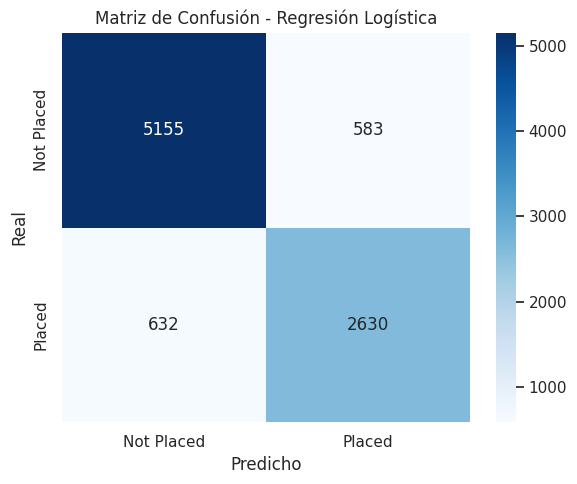

In [149]:
# ==============================================================================
# BLOQUE 7A: MATRIZ DE CONFUSIÓN
# ==============================================================================
# Predicciones con el modelo de Regresión Logística
y_pred_log = log_reg.predict(X_test_scaled)

# Cálculo de la Matriz de Confusión
cm_log = confusion_matrix(y_test, y_pred_log)

# Visualización de la Matriz de Confusión
plt.figure(figsize=(6, 5))
sns.heatmap(cm_log, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not Placed', 'Placed'],
            yticklabels=['Not Placed', 'Placed'])
plt.title('Matriz de Confusión - Regresión Logística')
plt.xlabel('Predicho')
plt.ylabel('Real')
plt.tight_layout()
plt.show()

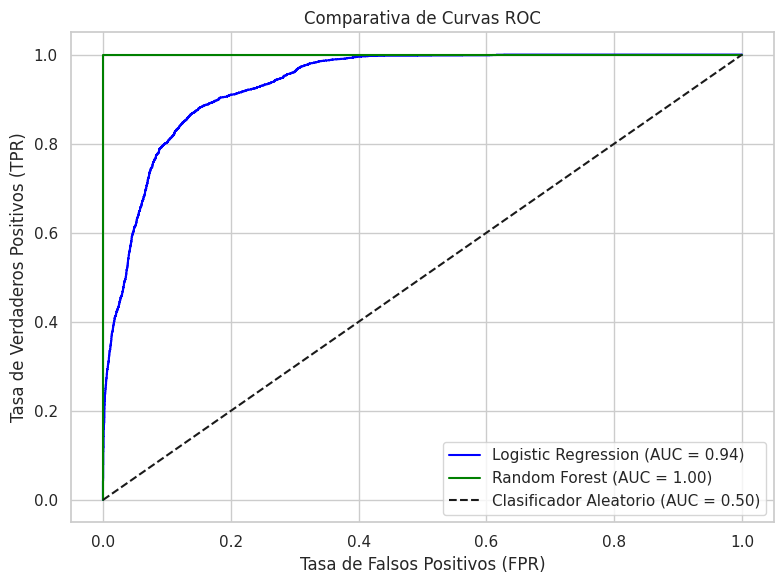

In [150]:
# ==============================================================================
# BLOQUE 8A: CURVA ROC COMPARATIVA
# ==============================================================================
plt.figure(figsize=(8, 6))

# Probabilidades de la clase positiva (Placed = 1)
y_proba_log = log_reg.predict_proba(X_test_scaled)[:, 1]
y_proba_rf = rf_model.predict_proba(X_test_scaled)[:, 1]

# Cálculo de ROC para Regresión Logística
fpr_log, tpr_log, _ = roc_curve(y_test, y_proba_log)
auc_log = roc_auc_score(y_test, y_proba_log)

# Cálculo de ROC para Random Forest
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_proba_rf)
auc_rf = roc_auc_score(y_test, y_proba_rf)

# Graficar curvas ROC
plt.plot(fpr_log, tpr_log, label=f'Logistic Regression (AUC = {auc_log:.2f})', color='blue')
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {auc_rf:.2f})', color='green')
plt.plot([0, 1], [0, 1], 'k--', label='Clasificador Aleatorio (AUC = 0.50)')

plt.title('Comparativa de Curvas ROC')
plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR)')
plt.legend(loc='lower right')
plt.grid(True)
plt.tight_layout()
plt.show()

/tmp/ipykernel_4644/2593582737.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=df_importance, palette='viridis')


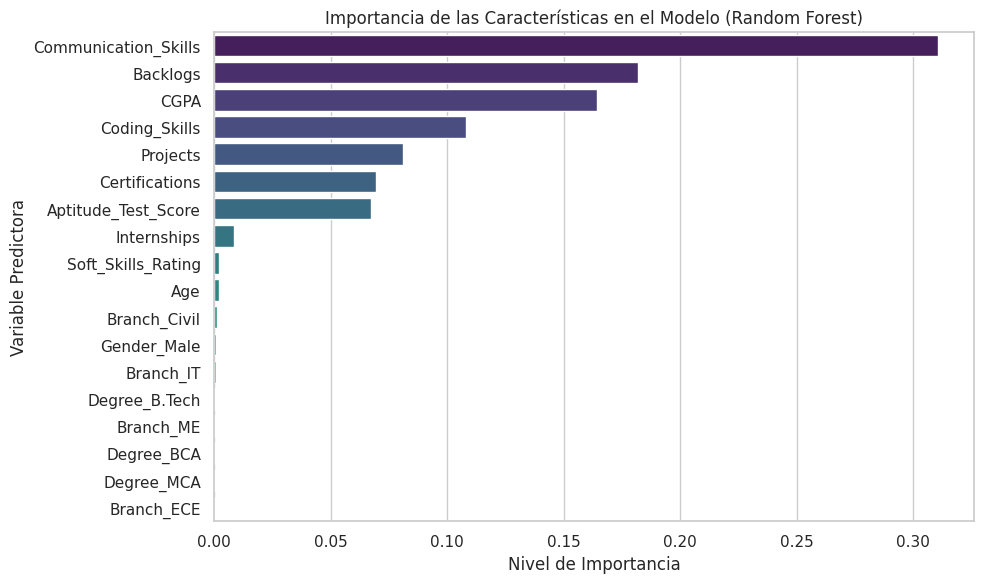

In [151]:
# ==============================================================================
# BLOQUE 8B: IMPORTANCIA DE CARACTERÍSTICAS (FEATURE IMPORTANCE)
# ==============================================================================
importances = rf_model.feature_importances_
feature_names = X.columns

df_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=df_importance, palette='viridis')
plt.title('Importancia de las Características en el Modelo (Random Forest)')
plt.xlabel('Nivel de Importancia')
plt.ylabel('Variable Predictora')
plt.tight_layout()
plt.show()